In [1]:
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns


In [2]:

# Find project directory whether notebook runs from root or notebooks/
cwd = Path.cwd()
PROJECT_DIR = cwd if (cwd / "dataset").exists() else cwd.parent

DATA_PATH = (
    PROJECT_DIR / "dataset" /
    "heart_failure_clinical_records_dataset.csv"
)

df = pd.read_csv("C:\\Users\\vaibh\\OneDrive\\Desktop\\Heart_Failure_Survival_Analysis\\dataset\\heart_failure_clinical_records_dataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)


Dataset loaded successfully!
Dataset shape: (299, 13)


In [3]:

# Display first five records
display(df.head())

# Display last five records
display(df.tail())

# Dataset dimensions
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
294,62.0,0,61,1,38,1,155000.0,1.1,143,1,1,270,0
295,55.0,0,1820,0,38,0,270000.0,1.2,139,0,0,271,0
296,45.0,0,2060,1,60,0,742000.0,0.8,138,0,0,278,0
297,45.0,0,2413,0,38,0,140000.0,1.4,140,1,1,280,0
298,50.0,0,196,0,45,0,395000.0,1.6,136,1,1,285,0


Rows: 299
Columns: 13


In [4]:

df.info()

print("\nStatistical summary:")
display(df.describe().T)


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB

Statistical summa

,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0


In [5]:

missing = df.isnull().sum()

missing_summary = pd.DataFrame({
    "Missing Values": missing,
    "Percentage": (missing / len(df)) * 100
})

display(missing_summary)


,Missing Values,Percentage
age,0,0.0
anaemia,0,0.0
creatinine_phosphokinase,0,0.0
diabetes,0,0.0
ejection_fraction,0,0.0
high_blood_pressure,0,0.0
platelets,0,0.0
serum_creatinine,0,0.0
serum_sodium,0,0.0
sex,0,0.0


In [6]:

print("Duplicate rows:", df.duplicated().sum())

df = df.drop_duplicates().copy()

print("Shape after removing duplicates:", df.shape)


Duplicate rows: 0
Shape after removing duplicates: (299, 13)


In [7]:

expected_columns = [
    "age", "anaemia", "creatinine_phosphokinase",
    "diabetes", "ejection_fraction",
    "high_blood_pressure", "platelets",
    "serum_creatinine", "serum_sodium",
    "sex", "smoking", "time", "DEATH_EVENT"
]

missing_columns = set(expected_columns) - set(df.columns)

if missing_columns:
    raise ValueError(f"Missing columns: {missing_columns}")

df = df[expected_columns].copy()

for col in expected_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print(df.dtypes)


age                         float64
anaemia                       int64
creatinine_phosphokinase      int64
diabetes                      int64
ejection_fraction             int64
high_blood_pressure           int64
platelets                   float64
serum_creatinine            float64
serum_sodium                  int64
sex                           int64
smoking                       int64
time                          int64
DEATH_EVENT                   int64
dtype: object


In [8]:

# Report missing values before removal
print("Missing values before cleaning:")
print(df.isnull().sum())

# Remove records with missing required fields
df = df.dropna(subset=expected_columns).copy()

# Validate binary fields
binary_cols = [
    "anaemia", "diabetes", "high_blood_pressure",
    "sex", "smoking", "DEATH_EVENT"
]

for col in binary_cols:
    df = df[df[col].isin([0, 1])].copy()

# Basic clinical and duration constraints
positive_cols = [
    "age", "ejection_fraction", "platelets",
    "serum_creatinine", "serum_sodium", "time"
]

for col in positive_cols:
    df = df[df[col] > 0].copy()

print("Shape after validation:", df.shape)


Missing values before cleaning:
age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64
Shape after validation: (299, 13)


In [9]:

print("Missing values:", df.isnull().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

display(df.describe().T)
display(df.head())


Missing values: 0
Duplicate rows: 0


,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0


,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


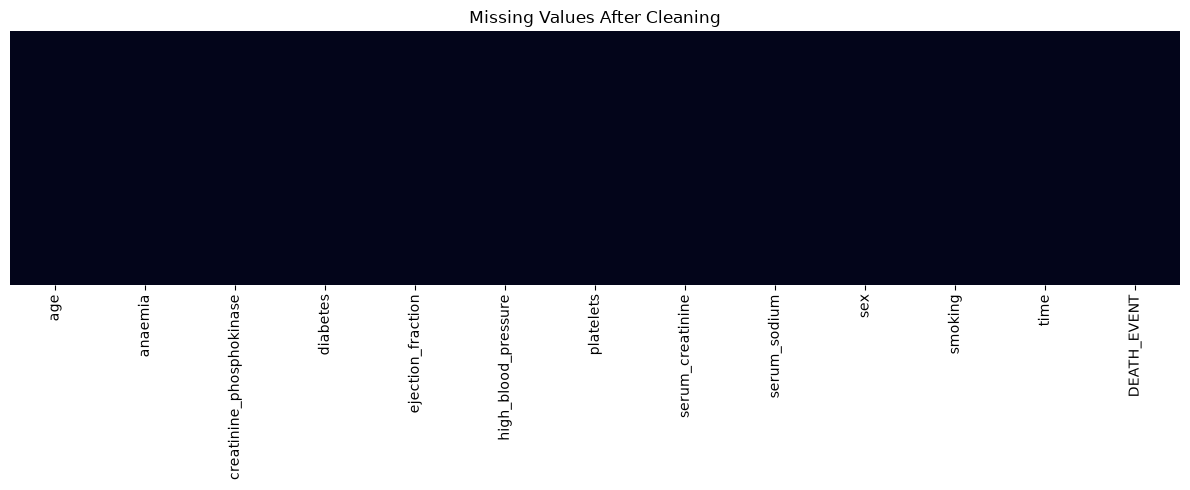

In [10]:

plt.figure(figsize=(12, 5))
sns.heatmap(df.isnull(), cbar=False, yticklabels=False)
plt.title("Missing Values After Cleaning")
plt.tight_layout()
plt.show()


In [11]:

OUTPUT_PATH = PROJECT_DIR / "dataset" / "heart_failure_cleaned.csv"

df.to_csv(OUTPUT_PATH, index=False)

print("Cleaned dataset saved:", OUTPUT_PATH)
print("Final shape:", df.shape)
print("Data cleaning completed!")


Cleaned dataset saved: c:\Users\vaibh\OneDrive\Desktop\Heart_Failure_Survival_Analysis\dataset\heart_failure_cleaned.csv
Final shape: (299, 13)
Data cleaning completed!
